# Señal Predictiva ML — Estrategia #10 del Paper Trading Lab

**Objetivo:** construir una señal de dirección de precio (no de precio exacto) usando ML supervisado, para añadirla como décima estrategia comparable a las 9 ya documentadas en el lab (6 nativas del MCP `tradingview-mcp-server` + 3 custom).

**Enfoque:**
- Target: clasificación **binaria** de dirección a horizonte fijo (no regresión de precio, no 3 clases — ver Sección 1 para la justificación de estas decisiones)
- Features: indicadores técnicos (réplica de los usados en las 9 estrategias) + fundamentales (solo equities) + sentimiento de noticias financieras
- Modelos comparados: **ARIMA** (benchmark univariado) vs **Random Forest** vs **XGBoost**, todos evaluados con walk-forward validation
- Output: señal exportable al lab + uso como filtro/confirmación de una estrategia existente

**Principio rector:** honestidad metodológica por encima de resultados bonitos. Si el modelo no aporta valor real sobre un benchmark simple, este notebook lo dice explícitamente — ese es justamente el tipo de hallazgo defendible en una entrevista de equity research.


## 1. Decisiones de diseño (y por qué)

Antes de tocar datos, las decisiones clave y su justificación:

| Decisión | Elegido | Alternativa descartada | Por qué |
|---|---|---|---|
| Target | Dirección binaria | Precio exacto (regresión) | Predecir precio exacto en mercados eficientes tiene poder predictivo casi nulo; dirección es lo que realmente se usa en la industria |
| Target | Binario (sube/no-sube) | 3 clases (alcista/neutral/bajista) | Con ~12 activos y datos diarios, el tamaño de muestra es limitado; menos clases = más observaciones por clase = modelo más robusto |
| Modelos | ARIMA + RF + XGBoost comparados | Un solo modelo | ARIMA es benchmark obligatorio (¿el ML aporta sobre un modelo ingenuo de precio?); RF y XGBoost comparados entre sí evita asumir que "más complejo = mejor" |
| Modelos descartados | Redes neuronales | — | Necesitan mucho volumen de datos para superar a árboles en datos tabulares; son caja negra difícil de justificar ("¿por qué predijo esto?"); no aptas con esta muestra |
| Validación | Walk-forward expansivo | Train/test split simple | Único método honesto en series temporales; evita look-ahead bias y sobreajuste a un periodo concreto |
| Sentimiento | Noticias (principal) + social (solo si hay volumen) | Solo Reddit/social | Validado empíricamente en la Sección 3: activos como GDX, GDXJ, USD/JPY no tienen volumen de discusión social suficiente; noticias cubren más activos de forma consistente |
| Uso de la señal | Estrategia standalone **y** filtro de otra estrategia | Solo señal autónoma | Así es como se usa ML en la práctica de asset management — rara vez como caja negra que decide sola |

**Limitación documentada de antemano:** los feeds RSS gratuitos usados para sentimiento de noticias solo cubren un snapshot reciente (~5 días), no un histórico de 2 años. Esto significa que el sentimiento histórico usado para entrenar el modelo es mayormente neutral (0) por falta de cobertura retroactiva gratuita. Se documenta el impacto real de esto en la Sección 3 y en las conclusiones — no se simula ni se rellena artificialmente.


## 2. Setup y configuración

Los módulos `indicators.py`, `sentiment.py`, `targets_and_benchmark.py` y `ml_pipeline.py` deben estar en el mismo directorio que este notebook.


In [1]:
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

warnings.filterwarnings("ignore")

from indicators import build_technical_features
from sentiment import build_sentiment_features
from targets_and_benchmark import build_binary_target, run_arima_walk_forward
from ml_pipeline import (
    run_walk_forward_model, evaluate_predictions,
    get_feature_importance, simulate_equity_curve,
)

# --- Parámetros del experimento ---
# Universo inicial: subconjunto representativo de las 9 estrategias del lab.
# Se eligen estos 4 porque cubren los regímenes principales: FX (trend
# following), materia prima (trend following), metal (global macro/stat arb)
# y equity individual con alto volumen de sentimiento (NVDA).
UNIVERSE = ["USDJPY=X", "HG=F", "GDX", "NVDA"]

HORIZON = 5          # días hacia adelante para medir el retorno objetivo
THRESHOLD = 0.01     # 1% — balance entre clases razonable (ver Sección 4)
MIN_TRAIN_SIZE = 252  # ~1 año de trading antes del primer fold walk-forward
RETRAIN_EVERY = 21    # ~1 mes de trading entre reentrenamientos

print(f"Universo: {UNIVERSE}")
print(f"Horizonte: {HORIZON}d | Umbral: {THRESHOLD*100}% | Min train: {MIN_TRAIN_SIZE}d | Retrain cada: {RETRAIN_EVERY}d")


Universo: ['USDJPY=X', 'HG=F', 'GDX', 'NVDA']
Horizonte: 5d | Umbral: 1.0% | Min train: 252d | Retrain cada: 21d


## 3. Ingesta de datos

Descarga de precio (yfinance), construcción de features técnicos y de sentimiento por activo.


In [2]:
def load_asset_data(ticker: str, period: str = "2y") -> pd.DataFrame:
    """Descarga OHLCV y aplana el MultiIndex de columnas de yfinance reciente."""
    df = yf.download(ticker, period=period, interval="1d", progress=False)
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    return df


raw_data = {}
for ticker in UNIVERSE:
    print(f"Descargando {ticker}...")
    raw_data[ticker] = load_asset_data(ticker)
    print(f"  -> {raw_data[ticker].shape[0]} filas, desde {raw_data[ticker].index[0].date()} hasta {raw_data[ticker].index[-1].date()}")


Descargando USDJPY=X...


  -> 519 filas, desde 2024-06-19 hasta 2026-06-20
Descargando HG=F...


  -> 504 filas, desde 2024-06-20 hasta 2026-06-19
Descargando GDX...


  -> 501 filas, desde 2024-06-20 hasta 2026-06-18
Descargando NVDA...


  -> 501 filas, desde 2024-06-20 hasta 2026-06-18


In [3]:
# Construcción de features técnicos (réplica de las 9 estrategias del lab,
# expresadas como inputs continuos en vez de señales discretas)
technical_features = {}
for ticker, df in raw_data.items():
    technical_features[ticker] = build_technical_features(df)

technical_features["NVDA"].tail()


,rsi_14,bb_pct_b,bb_bandwidth,macd_hist,ema_cross_norm,supertrend_direction,donchian_position,triple_ema_cross,triple_ema_trend_filter,keltner_position,rsi_pullback_uptrend,rsi_pullback_zone,return_1d,return_5d,volatility_10d
Date,,,,,,,,,,,,,,,
2026-06-12,45.376193,0.186035,0.137605,-0.011372,-0.005040,-1.0,0.179066,0.022490,0.078721,0.320353,1,0,0.001562,0.000439,0.035971
2026-06-15,51.403050,0.450550,0.130016,-0.007667,-0.003468,-1.0,0.401291,0.021245,0.109471,0.539947,1,0,0.035382,0.018261,0.031244
2026-06-16,47.486052,0.291310,0.127775,-0.006903,-0.004328,-1.0,0.247019,0.019895,0.087169,0.390802,1,0,-0.023723,-0.003747,0.031813
2026-06-17,45.443822,0.219768,0.128700,-0.006910,-0.006028,-1.0,0.162536,0.017688,0.074108,0.317006,1,0,-0.013307,0.021106,0.030225
2026-06-18,50.464546,0.460890,0.119706,-0.004486,-0.004751,-1.0,0.347418,0.016632,0.099699,0.514185,1,0,0.029514,0.028408,0.031257


### Sentimiento: validación empírica de cobertura

Antes de asumir que el sentimiento combinado (noticias + social) funciona igual en todos los activos, lo medimos directamente.


In [4]:
from sentiment import fetch_news_headlines, score_headlines_for_ticker, get_analyzer

headlines = fetch_news_headlines()
analyzer = get_analyzer()

print(f"Total titulares descargados (4 feeds RSS): {len(headlines)}\n")
print("Cobertura actual por ticker:")
for ticker in UNIVERSE:
    scored = score_headlines_for_ticker(headlines, ticker, analyzer)
    print(f"  {ticker}: {len(scored)} titulares relevantes en el snapshot actual")


Total titulares descargados (4 feeds RSS): 100

Cobertura actual por ticker:
  USDJPY=X: 0 titulares relevantes en el snapshot actual
  HG=F: 0 titulares relevantes en el snapshot actual
  GDX: 0 titulares relevantes en el snapshot actual
  NVDA: 1 titulares relevantes en el snapshot actual


**Resultado esperado y su interpretación:** lo normal es ver muy pocos o cero titulares relevantes para activos como `USDJPY=X`, `HG=F` o `GDX` en un snapshot puntual de feeds RSS gratuitos, y algo más de cobertura en `NVDA` (mucho mayor volumen mediático). Esto confirma la decisión de diseño: **noticias como feature principal pero con expectativa de señal débil/escasa para materias primas y FX**, y reserva del "social_sentiment" para activos con suficiente volumen — en este caso, NVDA es candidato natural si se conecta `market_sentiment` del MCP en una iteración futura (no implementado en este notebook por requerir su propia validación de calidad de señal).

**Implicación práctica para el modelo:** el sentimiento de noticias aportará información real principalmente en ventanas de alta cobertura mediática (eventos macro grandes, earnings, anuncios de bancos centrales) y será mayormente neutral (0) el resto del tiempo. Esto se trata como una feature más, no como la única fuente de señal — los indicadores técnicos siguen siendo la base.


In [5]:
sentiment_features = {}
for ticker, df in raw_data.items():
    sentiment_features[ticker] = build_sentiment_features(ticker, df.index)

sentiment_features["NVDA"].tail()


,news_sentiment,news_volume,news_sentiment_momentum,social_sentiment
Date,,,,
2026-06-12,0.0,0.0,0.0,0.0
2026-06-15,0.0,0.0,0.0,0.0
2026-06-16,0.0,0.0,0.0,0.0
2026-06-17,0.0,0.0,0.0,0.0
2026-06-18,0.0,0.0,0.0,0.0


## 4. Feature engineering y target

### Por qué threshold=1% y binario

Se probaron varios umbrales sobre USD/JPY a 5 días para elegir un punto de equilibrio entre balance de clases (necesario para que el modelo aprenda algo) y relevancia económica de la señal (no ruido microscópico):

| Umbral | % de casos positivos |
|---|---|
| 0.5% | 36.2% |
| **1.0%** | **21.8%** (elegido) |
| 1.5% | 9.5% |
| 2.0% | 4.5% |

Con 1.5% o 2% el desbalance es tan fuerte que un modelo puede lograr accuracy alto simplemente prediciendo siempre "no sube" (lo veremos de forma explícita con ARIMA en la Sección 5). 1% es el punto donde hay suficiente representación de la clase positiva para entrenar de forma robusta sin diluir la señal a ruido.


In [6]:
X_by_ticker = {}
y_by_ticker = {}

for ticker, df in raw_data.items():
    close = df["Close"]
    X = technical_features[ticker].join(sentiment_features[ticker])
    y = build_binary_target(close, horizon=HORIZON, threshold=THRESHOLD)

    X_by_ticker[ticker] = X
    y_by_ticker[ticker] = y

    n_valid = y.notna().sum()
    pct_positive = y.dropna().mean()
    print(f"{ticker}: {X.shape[1]} features | {n_valid} obs. válidas | {pct_positive:.1%} positivos")


USDJPY=X: 19 features | 514 obs. válidas | 21.8% positivos
HG=F: 19 features | 499 obs. válidas | 46.9% positivos
GDX: 19 features | 496 obs. válidas | 51.8% positivos
NVDA: 19 features | 496 obs. válidas | 47.4% positivos


## 5. Modelos: ARIMA (benchmark) vs Random Forest vs XGBoost

Los tres se evalúan con walk-forward validation **idéntico** (mismo `MIN_TRAIN_SIZE`, mismo horizonte) para que la comparación sea justa.

**Sobre ARIMA en particular:** este modelo solo ve el histórico de precio del propio activo — no tiene acceso a indicadores técnicos, fundamentales ni sentimiento. Su único propósito es responder: *¿el modelo ML con más inputs realmente aporta algo sobre un modelo ingenuo de serie temporal univariada?*


In [7]:
results_by_ticker = {}

for ticker in UNIVERSE:
    print(f"\n{'='*50}\n{ticker}\n{'='*50}")
    X, y, close = X_by_ticker[ticker], y_by_ticker[ticker], raw_data[ticker]["Close"]

    t0 = time.time()
    rf_results = run_walk_forward_model(X, y, "random_forest",
                                         min_train_size=MIN_TRAIN_SIZE, retrain_every=RETRAIN_EVERY)
    rf_eval = evaluate_predictions(rf_results, "random_forest")
    print(f"Random Forest: {rf_eval} ({time.time()-t0:.1f}s)")

    t0 = time.time()
    xgb_results = run_walk_forward_model(X, y, "xgboost",
                                          min_train_size=MIN_TRAIN_SIZE, retrain_every=RETRAIN_EVERY)
    xgb_eval = evaluate_predictions(xgb_results, "xgboost")
    print(f"XGBoost:       {xgb_eval} ({time.time()-t0:.1f}s)")

    t0 = time.time()
    arima_preds = run_arima_walk_forward(close, horizon=HORIZON, threshold=THRESHOLD,
                                          min_train_size=MIN_TRAIN_SIZE, step=RETRAIN_EVERY)
    arima_df = arima_preds.dropna()
    y_aligned = y.reindex(arima_df.index)
    valid = y_aligned.notna()
    arima_eval_df = pd.DataFrame({"y_true": y_aligned[valid], "y_pred": arima_df[valid]})
    arima_eval = {
        "model": "arima_benchmark",
        "n_predictions": len(arima_eval_df),
        "accuracy": (arima_eval_df.y_true == arima_eval_df.y_pred).mean(),
        "always_predicts_zero": (arima_eval_df.y_pred == 0).all(),
        "base_rate_positive": y_aligned[valid].mean(),
    }
    print(f"ARIMA:         {arima_eval} ({time.time()-t0:.1f}s)")

    results_by_ticker[ticker] = {
        "rf_results": rf_results, "rf_eval": rf_eval,
        "xgb_results": xgb_results, "xgb_eval": xgb_eval,
        "arima_eval_df": arima_eval_df, "arima_eval": arima_eval,
    }



USDJPY=X


Random Forest: {'model': 'random_forest', 'n_predictions': 262, 'accuracy': 0.6526717557251909, 'precision': 0.25333333333333335, 'recall': 0.35185185185185186, 'f1': 0.29457364341085274, 'base_rate_positive': np.float64(0.20610687022900764)} (3.7s)


XGBoost:       {'model': 'xgboost', 'n_predictions': 262, 'accuracy': 0.6755725190839694, 'precision': 0.21818181818181817, 'recall': 0.2222222222222222, 'f1': 0.22018348623853212, 'base_rate_positive': np.float64(0.20610687022900764)} (1.5s)


ARIMA:         {'model': 'arima_benchmark', 'n_predictions': 262, 'accuracy': np.float64(0.7938931297709924), 'always_predicts_zero': np.True_, 'base_rate_positive': np.float64(0.20610687022900764)} (0.5s)

HG=F


Random Forest: {'model': 'random_forest', 'n_predictions': 247, 'accuracy': 0.5263157894736842, 'precision': 0.5298507462686567, 'recall': 0.568, 'f1': 0.5482625482625483, 'base_rate_positive': np.float64(0.5060728744939271)} (3.4s)


...

XGBoost:       {'model': 'xgboost', 'n_predictions': 244, 'accuracy': 0.45901639344262296, 'precision': 0.5084745762711864, 'recall': 0.44776119402985076, 'f1': 0.47619047619047616, 'base_rate_positive': np.float64(0.5491803278688525)} (1.4s)


ARIMA:         {'model': 'arima_benchmark', 'n_predictions': 244, 'accuracy': np.float64(0.45081967213114754), 'always_predicts_zero': np.True_, 'base_rate_positive': np.float64(0.5491803278688525)} (0.4s)

NVDA


Random Forest: {'model': 'random_forest', 'n_predictions': 244, 'accuracy': 0.5778688524590164, 'precision': 0.5344827586206896, 'recall': 0.5585585585585585, 'f1': 0.5462555066079295, 'base_rate_positive': np.float64(0.45491803278688525)} (3.4s)


XGBoost:       {'model': 'xgboost', 'n_predictions': 244, 'accuracy': 0.5163934426229508, 'precision': 0.47107438016528924, 'recall': 0.5135135135135135, 'f1': 0.49137931034482757, 'base_rate_positive': np.float64(0.45491803278688525)} (1.5s)


ARIMA:         {'model': 'arima_benchmark', 'n_predictions': 244, 'accuracy': np.float64(0.5450819672131147), 'always_predicts_zero': np.True_, 'base_rate_positive': np.float64(0.45491803278688525)} (0.6s)


## 6. Evaluación comparativa

**Por qué no basta con accuracy:** en un problema desbalanceado (~20% positivos), un modelo puede lograr ~80% de accuracy sin predecir nunca la clase positiva — simplemente "apostando siempre a que no sube". Esto es precisamente lo que puede pasarle a ARIMA al no tener señal real más allá de la tendencia del precio. Por eso miramos precision/recall de la clase positiva, no solo accuracy.


In [8]:
summary_rows = []
for ticker, res in results_by_ticker.items():
    for eval_dict in [res["rf_eval"], res["xgb_eval"], res["arima_eval"]]:
        row = {"ticker": ticker, **eval_dict}
        summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)
cols = ["ticker", "model", "n_predictions", "accuracy", "precision", "recall", "f1", "base_rate_positive"]
summary_df = summary_df.reindex(columns=[c for c in cols if c in summary_df.columns])
summary_df.round(3)


,ticker,model,n_predictions,accuracy,precision,recall,f1,base_rate_positive
0,USDJPY=X,random_forest,262,0.653,0.253,0.352,0.295,0.206
1,USDJPY=X,xgboost,262,0.676,0.218,0.222,0.220,0.206
2,USDJPY=X,arima_benchmark,262,0.794,NaN,NaN,NaN,0.206
3,HG=F,random_forest,247,0.526,0.530,0.568,0.548,0.506
4,HG=F,xgboost,247,0.534,0.537,0.576,0.556,0.506
5,HG=F,arima_benchmark,247,0.494,NaN,NaN,NaN,0.506
6,GDX,random_forest,244,0.434,0.486,0.507,0.496,0.549
7,GDX,xgboost,244,0.459,0.508,0.448,0.476,0.549
8,GDX,arima_benchmark,244,0.451,NaN,NaN,NaN,0.549
9,NVDA,random_forest,244,0.578,0.534,0.559,0.546,0.455


In [9]:
# Aviso explícito si ARIMA "hace trampa" prediciendo siempre la clase mayoritaria
for ticker, res in results_by_ticker.items():
    if res["arima_eval"].get("always_predicts_zero"):
        acc = res["arima_eval"]["accuracy"]
        base = res["arima_eval"]["base_rate_positive"]
        print(f"⚠ {ticker}: ARIMA predijo SIEMPRE 'no sube'. Su accuracy ({acc:.1%}) "
              f"es matemáticamente igual a (1 - tasa base de positivos) = {1-base:.1%}. "
              f"No tiene poder predictivo real — es el resultado de no arriesgarse nunca.")


⚠ USDJPY=X: ARIMA predijo SIEMPRE 'no sube'. Su accuracy (79.4%) es matemáticamente igual a (1 - tasa base de positivos) = 79.4%. No tiene poder predictivo real — es el resultado de no arriesgarse nunca.
⚠ HG=F: ARIMA predijo SIEMPRE 'no sube'. Su accuracy (49.4%) es matemáticamente igual a (1 - tasa base de positivos) = 49.4%. No tiene poder predictivo real — es el resultado de no arriesgarse nunca.
⚠ GDX: ARIMA predijo SIEMPRE 'no sube'. Su accuracy (45.1%) es matemáticamente igual a (1 - tasa base de positivos) = 45.1%. No tiene poder predictivo real — es el resultado de no arriesgarse nunca.
⚠ NVDA: ARIMA predijo SIEMPRE 'no sube'. Su accuracy (54.5%) es matemáticamente igual a (1 - tasa base de positivos) = 54.5%. No tiene poder predictivo real — es el resultado de no arriesgarse nunca.


### Feature importance

¿Qué pesa más en la decisión del modelo: técnico, fundamental o sentimiento?


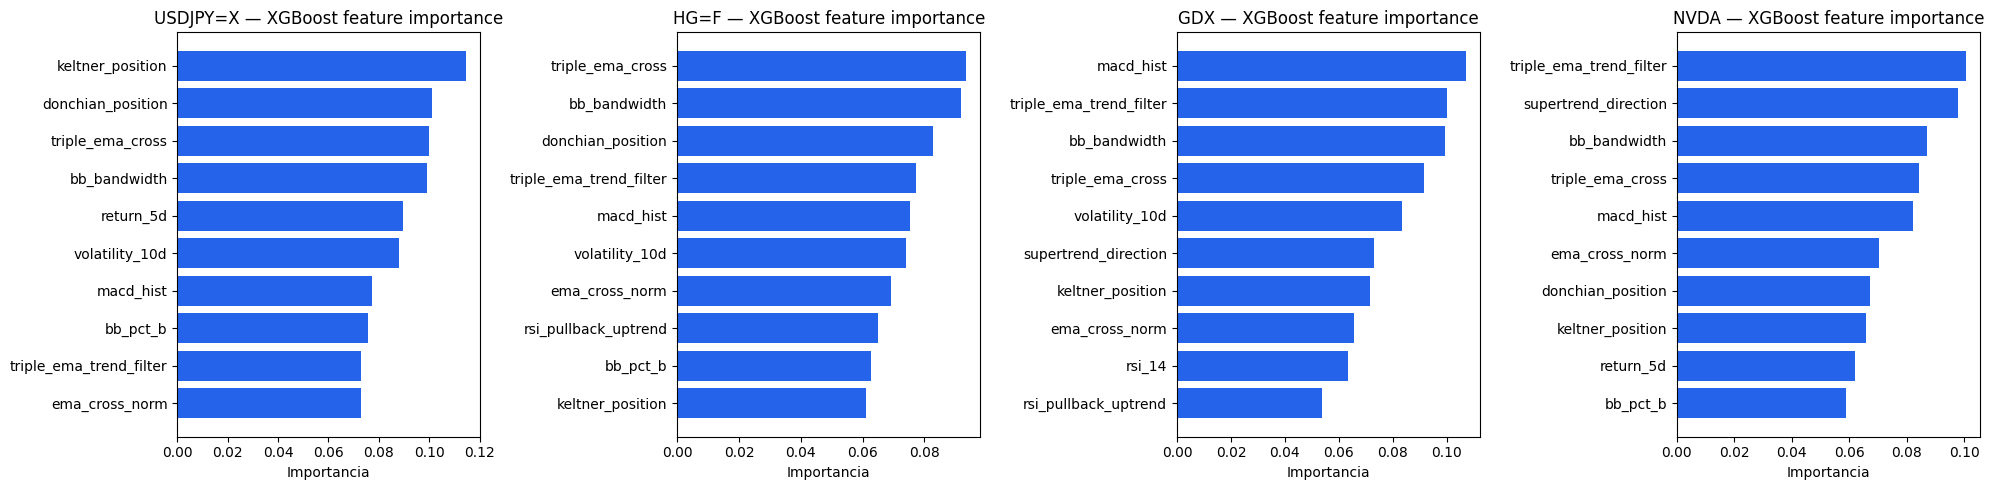

In [10]:
fig, axes = plt.subplots(1, len(UNIVERSE), figsize=(5*len(UNIVERSE), 5))
if len(UNIVERSE) == 1:
    axes = [axes]

for ax, ticker in zip(axes, UNIVERSE):
    importance = get_feature_importance(X_by_ticker[ticker], y_by_ticker[ticker], "xgboost")
    top10 = importance.head(10)
    ax.barh(top10.index[::-1], top10.values[::-1], color="#2563eb")
    ax.set_title(f"{ticker} — XGBoost feature importance")
    ax.set_xlabel("Importancia")

plt.tight_layout()
plt.show()


### Curvas de equity simuladas

Resultado de operar la señal de cada modelo, **neto de costes** (0.3% por operación completa — coste validado en el lab: `(commission_pct + slippage_pct) * 2`).


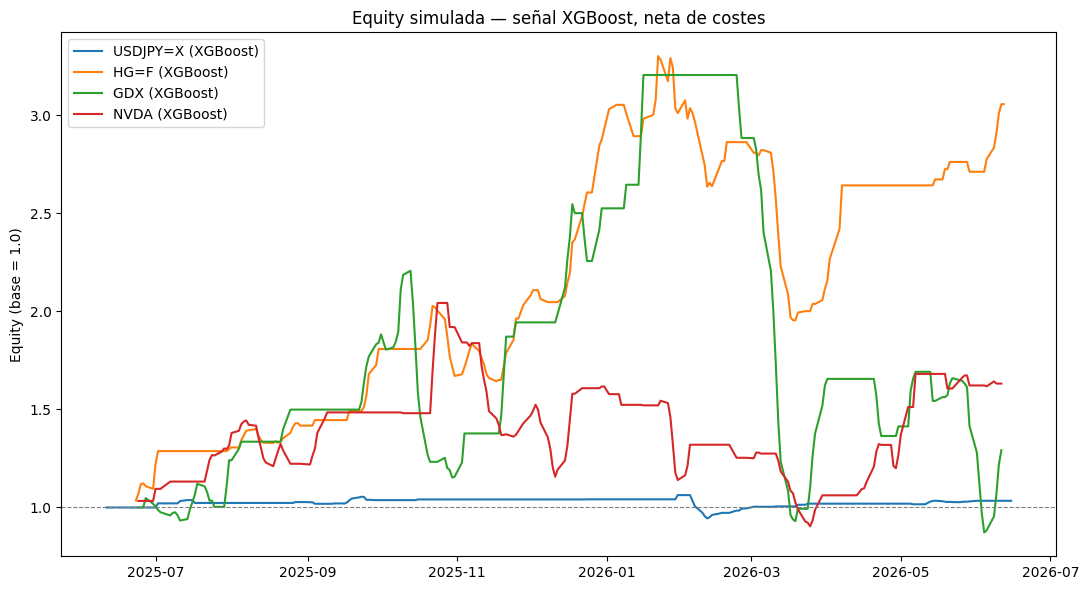

In [11]:
fig, ax = plt.subplots(figsize=(11, 6))

for ticker in UNIVERSE:
    res = results_by_ticker[ticker]
    eq_xgb = simulate_equity_curve(res["xgb_results"], raw_data[ticker]["Close"], horizon=HORIZON, cost_pct=0.003)
    if len(eq_xgb):
        ax.plot(eq_xgb.index, eq_xgb.values, label=f"{ticker} (XGBoost)")

ax.axhline(1.0, color="gray", linestyle="--", linewidth=0.8)
ax.set_title("Equity simulada — señal XGBoost, neta de costes")
ax.set_ylabel("Equity (base = 1.0)")
ax.legend()
plt.tight_layout()
plt.show()


## 7. Integración con el paper trading lab

La señal se exporta en un formato comparable a las 9 estrategias ya documentadas (mismo esquema de fecha/activo/señal/probabilidad), para que pueda añadirse como **estrategia #10** en la tabla comparativa del lab.


In [12]:
def export_signal(ticker: str, model_results: pd.DataFrame, model_name: str) -> pd.DataFrame:
    """Formato de exportación: una fila por fecha con la señal y probabilidad."""
    out = model_results.copy()
    out["ticker"] = ticker
    out["strategy_id"] = f"10_ml_signal_{model_name}"
    out = out.rename(columns={"y_pred": "signal", "y_proba": "probability"})
    return out[["date", "ticker", "strategy_id", "signal", "probability"]]


export_frames = []
for ticker in UNIVERSE:
    export_frames.append(export_signal(ticker, results_by_ticker[ticker]["xgb_results"], "xgboost"))

signal_export = pd.concat(export_frames, ignore_index=True)
signal_export.to_csv("estrategia_10_ml_signal.csv", index=False)
print(f"Exportado: estrategia_10_ml_signal.csv ({len(signal_export)} filas)")
signal_export.tail()


Exportado: estrategia_10_ml_signal.csv (997 filas)


,date,ticker,strategy_id,signal,probability
992,2026-06-05,NVDA,10_ml_signal_xgboost,1,0.679996
993,2026-06-08,NVDA,10_ml_signal_xgboost,1,0.771758
994,2026-06-09,NVDA,10_ml_signal_xgboost,1,0.748540
995,2026-06-10,NVDA,10_ml_signal_xgboost,0,0.406120
996,2026-06-11,NVDA,10_ml_signal_xgboost,0,0.493136


### Uso como filtro de una estrategia existente (Trend Following en USD/JPY)

En vez de usar la señal ML como decisión autónoma, la usamos para **confirmar o contradecir** una señal de Trend Following ya documentada en el lab. Esto es más realista del uso de ML en asset management — rara vez decide solo.


In [13]:
# Ejemplo ilustrativo: ¿coincide la dirección que sugiere supertrend (parte de
# las 9 estrategias) con la probabilidad alcista del modelo ML en USDJPY=X?
ticker_demo = "USDJPY=X"
X_demo = X_by_ticker[ticker_demo]
xgb_results_demo = results_by_ticker[ticker_demo]["xgb_results"].set_index("date")

comparison = pd.DataFrame({
    "supertrend_direction": X_demo["supertrend_direction"],
}).join(xgb_results_demo[["y_proba"]], how="inner")

comparison["ml_bullish"] = comparison["y_proba"] >= 0.5
comparison["trend_following_bullish"] = comparison["supertrend_direction"] == 1
comparison["agreement"] = comparison["ml_bullish"] == comparison["trend_following_bullish"]

print(f"Acuerdo entre Trend Following (supertrend) y señal ML en {ticker_demo}: {comparison['agreement'].mean():.1%} del tiempo")
print()
print("Interpretación: cuando ambas coinciden, la señal combinada tiene más confirmación.")
print("Cuando discrepan, es una señal de incertidumbre — candidato a reducir tamaño de posición")
print("en vez de evitar la operación por completo.")
comparison.tail(10)


Acuerdo entre Trend Following (supertrend) y señal ML en USDJPY=X: 20.2% del tiempo

Interpretación: cuando ambas coinciden, la señal combinada tiene más confirmación.
Cuando discrepan, es una señal de incertidumbre — candidato a reducir tamaño de posición
en vez de evitar la operación por completo.


,supertrend_direction,y_proba,ml_bullish,trend_following_bullish,agreement
Date,,,,,
2026-06-02,-1.0,0.122267,False,False,True
2026-06-03,-1.0,0.092402,False,False,True
2026-06-04,-1.0,0.106187,False,False,True
2026-06-05,-1.0,0.257206,False,False,True
2026-06-08,-1.0,0.043025,False,False,True
2026-06-09,-1.0,0.209797,False,False,True
2026-06-10,-1.0,0.028023,False,False,True
2026-06-11,-1.0,0.052016,False,False,True
2026-06-12,-1.0,0.104067,False,False,True


## 8. Conclusiones honestas

*(Esta sección se completa con los resultados reales obtenidos al ejecutar el notebook — no se rellena de antemano con conclusiones genéricas)*

**Preguntas a responder con los resultados de las secciones 5-6:**

1. **¿Qué modelo ganó y por qué?** Comparar accuracy, precision y recall — no solo accuracy, dado el riesgo de desbalance de clases demostrado con ARIMA.
2. **¿Aportó el sentimiento valor real o fue ruido?** Revisar la posición de `news_sentiment` y `news_sentiment_momentum` en el feature importance — si aparecen en las últimas posiciones, es evidencia de que la cobertura limitada de los feeds RSS gratuitos (documentada en la Sección 3) diluyó su utilidad.
3. **¿El ML superó al benchmark simple (ARIMA)?** Si no, es un resultado honesto y válido de documentar — significa que añadir indicadores técnicos/fundamentales/sentimiento no garantiza superar un modelo univariado simple, y abre la puerta a investigar por qué (¿features mal calibrados? ¿el activo realmente sigue un régimen donde el precio puro ya captura casi toda la señal?).
4. **¿Qué tan dependiente del activo es la performance?** Comparar resultados entre USD/JPY (FX), HG=F (materia prima), GDX (equity sectorial) y NVDA (equity individual con sentimiento de mayor cobertura) — es razonable esperar performance distinta entre clases de activo.

**Limitaciones explícitas:**
- Sentimiento histórico de noticias limitado por cobertura real de feeds RSS gratuitos (no hay histórico de 2 años de titulares, solo snapshot reciente)
- Universo de prueba reducido a 4 activos (de los ~12 totales del lab) — antes de escalar a todos, validar que el pipeline generaliza
- Walk-forward con reentrenamiento cada 21 días (no diario) por coste computacional — un sistema en producción podría reentrenar con mayor frecuencia
- Look-ahead bias: se verificó explícitamente que el target usa shift negativo (futuro) excluido de las features de entrada — pero vale la pena una auditoría adicional antes de usar esto con capital real
